# Сегментация солнечных филаментов

## Описание задачи

Разработать алгоритм новый/существующий который генерирует точные сегментационные маски для отдельных солнечных нитей. Для каждой филамента предсказанная маска должна охватывать полный объем нити, включая её мелкомасштабные структуры, минимизируя включение нефиламентных областей. Задача направлена на надёжное и точное определение морфологии филамента в различных солнечных наблюдениях.



## Каковы основные трудности?
Хотя недавние достижения в сегментации объектов привели к впечатляющей производительности во многих областях, сегментация солнечных филаментов остаётся сложной задачей по нескольким причинам:

- **Тонкомасштабные конструкции**. Точное запечатление тонких структур нити, таких как зазубры, остаётся сложным. Зазубцы — это тонкие, ниточкообразные элементы, которые тянутся от основного тела нити по характерной ориентации. Их ориентация относительно позвоночника нити содержит важную информацию о расположении магнитного поля нити.
- **Фоновый шум и качество изображения**. Отличие материала филамента (тёмных областей) от фоновых структур и шума непросто. Поскольку наблюдения, используемые в этом конкурсе, исходят из наземных обсерваторий, они подвержены влиянию различных источников шума и артефактов изображения. Точная идентификация мелкомасштабных структур филаментов при подавлении фоновых шумов остаётся серьёзной задачей.
- **Структурная преемственность.** Существующие алгоритмы сегментации часто испытывают трудности с идентификацией солнечных нитей как смежных физических структур. Вместо этого они могут создавать фрагментированные сегментации или сегментные кластеры близлежащих тёмных областей («островков»), что приводит к неполным или физически несогласованным представлениям морфологии филамента.

Поданные материалы будут оцениваться по наземным данным (MAGFiLO) с использованием метрики Паноптического качества, которая определяется следующим образом:

$$
\mathrm{PQ}(Y,\hat{Y}) =
\frac{\sum_{(y,\hat{y}) \in TP} \mathrm{IoU}(y,\hat{y})}
{|TP| + 0.5|FP| + 0.5|FN|}
$$

где
- Y — множество всех сегментов основной истины y,
- Y-hat — это множество всех предсказанных сегментов y-hat,
- IoU вычисляет пересечение над унионом, как показано ниже,
- TP, FP и FN обозначают множества всех истинно положительных, ложноположительных и ложноотрицательных случаев соответственно, и
- |.| — операция мощности множества.

Пересечение над Юнион измеряется следующим образом:

$$
\mathrm{IoU}(y,\hat{y}) =
\frac{|y \cap \hat{y}|}{|y \cup \hat{y}|}
=
\frac{\sum (y \odot \hat{y})}
{\sum (y + \hat{y} - y \odot \hat{y})}
$$

## Импортирование библиотек

In [21]:
import time
import copy
import json
import random
from pathlib import Path
from collections import defaultdict
from functools import lru_cache

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import albumentations as A
import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from pycocotools import mask as mask_utils
from IPython.display import clear_output

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
plt.rcParams['figure.figsize'] = (15, 4)

## Загрузка GPU

In [22]:
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## Пути для работы с данными

In [23]:
data_dir = Path("data") / "MAGFiLO_1.0_Kaggle_2026"
train_dir = data_dir / "train" / "train_images"
train_json = data_dir / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
test_dir = data_dir / "test" / "test_images"

train_paths = sorted(train_dir.glob("*.jpeg"))
test_paths = sorted(test_dir.glob("*.jpeg"))

print("train:", len(train_paths))
print("test:", len(test_paths))

train: 707
test: 180


## Работа с данными

Структура данных: 

| Свойство | Результат |
|---|---|
| Обучающие изображения | 707 файлов |
| Тестовые изображения | 180 файлов |
| Формат и размер | JPEG, 2048 × 2048 |
| Каналы | Один: оттенки серого |
| Значения пикселей при чтении | шкала 0–255 |
| Разметка | JSON в формате COCO, 8199 объектов |
| Маски | Хранятся как координаты полигонов|

### Annotation records

In [24]:
with train_json.open(encoding='utf-8') as f:
    coco = json.load(f)

records = sorted(coco['images'], key=lambda x: (x['file_name'], x['id']))
annotations_by_id = defaultdict(list)
records_by_file = defaultdict(list)

for ann in coco['annotations']:
    annotations_by_id[ann['image_id']].append(ann)

for i, record in enumerate(records):
    records_by_file[record['file_name']].append(i)

print(f'{len(records_by_file)} images, {len(records)} annotator records')

707 images, 1154 annotator records


In [25]:
@lru_cache(maxsize=None)
def get_rles(index):
    record = records[int(index)]
    rles = []

    for ann in annotations_by_id[record['id']]:
        if ann['segmentation']:
            polygons = mask_utils.frPyObjects(ann['segmentation'],
                                             record['height'], record['width'])
            rles.append(mask_utils.merge(polygons))

    return rles


def load_train_sample(index):
    record = records[int(index)]
    with Image.open(train_dir / record['file_name']) as img:
        image = np.array(img.convert('L'), dtype=np.float32) / 255.0

    rles = get_rles(index)
    mask = mask_utils.decode(mask_utils.merge(rles)) if rles else np.zeros(image.shape, np.uint8)
    return image, mask

In [26]:
train_files, val_files = train_test_split(sorted(records_by_file), test_size=0.2, random_state=42)

train_indices = np.array([i for name in train_files for i in records_by_file[name]])
val_indices = np.array([i for name in val_files for i in records_by_file[name]])

print(f'train: {len(train_files)} images, {len(train_indices)} records')
print(f'val: {len(val_files)} images, {len(val_indices)} records')

train: 565 images, 922 records
val: 142 images, 232 records


## Preprocessing

In [27]:
def resize_data(indices, size=(1024, 1024)):
    images, masks = [], []
    for index in tqdm(indices):
        image, mask = load_train_sample(index)
        images.append(cv2.resize(image, size, interpolation=cv2.INTER_AREA))
        masks.append(cv2.resize(mask, size, interpolation=cv2.INTER_NEAREST))

    return np.array(images, dtype=np.float32), np.array(masks, dtype=np.uint8)


train_images, train_masks = resize_data(train_indices)
val_images, val_masks = resize_data(val_indices)
print(train_images.shape, val_images.shape)

100%|██████████| 232/232 [00:07<00:00, 32.08it/s]


(922, 1024, 1024) (232, 1024, 1024)


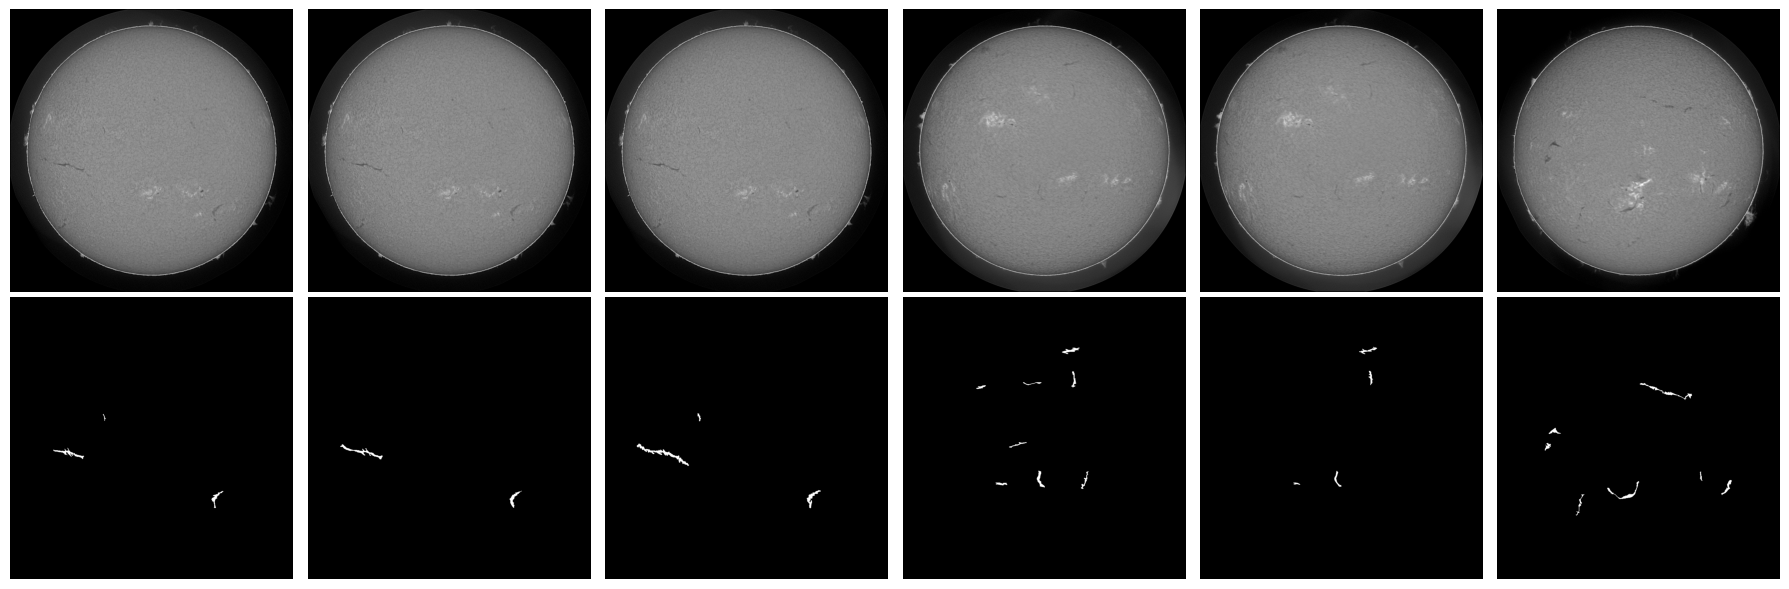

In [28]:
plt.figure(figsize=(18, 6))
for i in range(6):
    plt.subplot(2, 6, i + 1)
    plt.axis('off')
    plt.imshow(train_images[i], cmap='gray', vmin=0, vmax=1)

    plt.subplot(2, 6, i + 7)
    plt.axis('off')
    plt.imshow(train_masks[i], cmap='gray', vmin=0, vmax=1)

plt.tight_layout()
plt.show()

## Augmentation

In [9]:
transform = A.Compose([A.HorizontalFlip(p=0.5),
                       A.VerticalFlip(p=0.5),
                       A.RandomRotate90(p=0.5),
                       A.RandomBrightnessContrast(brightness_limit=0.1,
                                                  contrast_limit=0.15, p=0.8)], seed=42)

aug_images, aug_masks = [], []
for i in tqdm(range(len(train_images))):
    transformed = transform(image=train_images[i], mask=train_masks[i])
    aug_images.append(transformed['image'])
    aug_masks.append(transformed['mask'])

train_images = np.concatenate((train_images, aug_images), axis=0)
train_masks = np.concatenate((train_masks, aug_masks), axis=0)
train_indices = np.concatenate((train_indices, train_indices))

print(f'after augmentation: {len(train_images)} train records')
del aug_images, aug_masks

100%|██████████| 922/922 [00:11<00:00, 79.45it/s]


after augmentation: 1844 train records


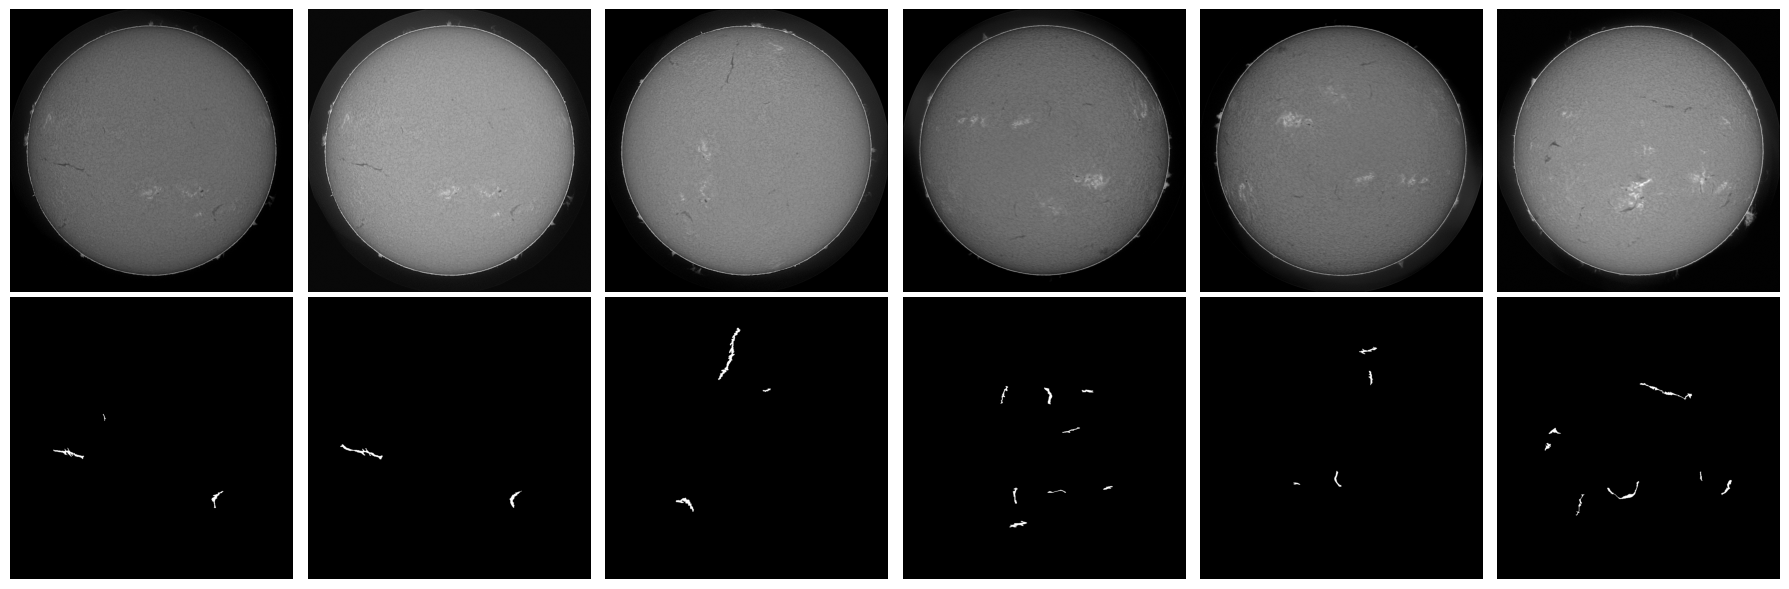

In [10]:
plt.figure(figsize=(18, 6))
start = len(train_images) // 2
for i in range(6):
    plt.subplot(2, 6, i + 1)
    plt.axis('off')
    plt.imshow(train_images[start + i], cmap='gray', vmin=0, vmax=1)

    plt.subplot(2, 6, i + 7)
    plt.axis('off')
    plt.imshow(train_masks[start + i], cmap='gray', vmin=0, vmax=1)

plt.tight_layout()
plt.show()

## Dataloaders

In [29]:
train_data = TensorDataset(torch.from_numpy(train_images).unsqueeze(1),
                           torch.from_numpy(train_masks).unsqueeze(1),
                           torch.from_numpy(train_indices))
val_data = TensorDataset(torch.from_numpy(val_images).unsqueeze(1),
                         torch.from_numpy(val_masks).unsqueeze(1),
                         torch.from_numpy(val_indices))

data_tr = DataLoader(train_data, batch_size=4, shuffle=True)
data_val = DataLoader(val_data, batch_size=4, shuffle=False)

dataset_sizes = {'train': len(train_data), 'val': len(val_data)}
print(dataset_sizes)
del train_images, train_masks, val_images, val_masks

{'train': 922, 'val': 232}


In [30]:
images, masks, indices = next(iter(data_tr))
print('images:', images.shape, images.dtype)
print('masks:', masks.shape, masks.dtype)
print('record indices:', indices)

images: torch.Size([4, 1, 1024, 1024]) torch.float32
masks: torch.Size([4, 1, 1024, 1024]) torch.uint8
record indices: tensor([ 564,  540,   46, 1022])


## U-Net

In [31]:
class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, features=32):
        super().__init__()

        self.encoder1 = self.one_block(in_channels, features)
        self.encoder2 = self.one_block(features, features * 2)
        self.encoder3 = self.one_block(features * 2, features * 4)
        self.encoder4 = self.one_block(features * 4, features * 8)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = self.one_block(features * 8, features * 16)

        self.upconv4 = nn.ConvTranspose2d(features * 16, features * 8, 2, stride=2)
        self.decoder4 = self.one_block(features * 16, features * 8)
        self.upconv3 = nn.ConvTranspose2d(features * 8, features * 4, 2, stride=2)
        self.decoder3 = self.one_block(features * 8, features * 4)
        self.upconv2 = nn.ConvTranspose2d(features * 4, features * 2, 2, stride=2)
        self.decoder2 = self.one_block(features * 4, features * 2)
        self.upconv1 = nn.ConvTranspose2d(features * 2, features, 2, stride=2)
        self.decoder1 = self.one_block(features * 2, features)

        self.conv = nn.Conv2d(features, out_channels, 1)

    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))
        bottleneck = self.bottleneck(self.pool(e4))

        d4 = self.decoder4(torch.cat((self.upconv4(bottleneck), e4), dim=1))
        d3 = self.decoder3(torch.cat((self.upconv3(d4), e3), dim=1))
        d2 = self.decoder2(torch.cat((self.upconv2(d3), e2), dim=1))
        d1 = self.decoder1(torch.cat((self.upconv1(d2), e1), dim=1))

        return torch.sigmoid(self.conv(d1))

    @staticmethod
    def one_block(in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

In [32]:
model = UNet(in_channels=1, out_channels=1, features=32).to(device)
print(f'parameters: {sum(p.numel() for p in model.parameters()):,}')

images, masks, indices = next(iter(data_tr))
model.eval()
with torch.no_grad():
    predictions = model(images.to(device))

print('input:', images.shape)
print('output:', predictions.shape)
model.train()
del predictions

parameters: 7,762,465
input: torch.Size([4, 1, 1024, 1024])
output: torch.Size([4, 1, 1024, 1024])


## Dice Loss / Dice Score

U-Net returns probabilities via sigmoid. Dice is an auxiliary pixel metric at the model input resolution, not the competition score.

In [33]:
def dice_score(y_true, y_pred, smoothing=1e-6):
    intersection = (y_true * y_pred).sum()
    union = y_true.sum() + y_pred.sum()
    return (2 * intersection + smoothing) / (union + smoothing)


class DiceScore:
    def __init__(self, threshold=0.5, smoothing=1e-6):
        self.name = 'DSC'
        self.threshold = threshold
        self.smoothing = smoothing

    @torch.no_grad()
    def __call__(self, y_true, y_pred):
        y_true = y_true.flatten(1).float()
        y_pred = (y_pred >= self.threshold).flatten(1).float()
        intersection = (y_true * y_pred).sum(1)
        union = y_true.sum(1) + y_pred.sum(1)
        return ((2 * intersection + self.smoothing) / (union + self.smoothing)).mean().item()


class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, y_pred, y_true):
        y_pred = y_pred.flatten(1)
        y_true = y_true.flatten(1).float()
        intersection = (y_pred * y_true).sum(1)
        union = y_pred.sum(1) + y_true.sum(1)
        return 1 - ((2 * intersection + self.smooth) / (union + self.smooth)).mean()

## Instance Masks / PQ

Baseline instances are 8-connected components of the thresholded probability map. They do not overlap. One disconnected annotated filament may be split; touching filaments may merge. No chirality classification is required.

PQ follows the organizer notebook: strict `IoU > 0.5`, all qualifying pairs, unmatched columns = FP, unmatched rows = FN. Counts are pooled over independent annotator records before computing PQ, rather than averaging image scores. No extra one-to-one assignment is introduced. Empty total denominator returns zero.

In [34]:
def probability_to_rles(probability, shape=(2048, 2048), threshold=0.5, min_area=32):
    height, width = shape
    probability = cv2.resize(probability, (width, height), interpolation=cv2.INTER_LINEAR)
    binary = (probability >= threshold).astype(np.uint8)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)

    return [mask_utils.encode(np.asfortranarray(labels == i, dtype=np.uint8))
            for i in range(1, count) if stats[i, cv2.CC_STAT_AREA] >= min_area]


def pq_counts(gt_rles, pred_rles):
    iou = mask_utils.iou(pred_rles, gt_rles, [0] * len(gt_rles)).T if gt_rles and pred_rles else np.zeros((len(gt_rles), len(pred_rles)))
    hits = iou > 0.5
    counts = np.array([iou[hits].sum(), hits.sum(),
                       (~hits.any(0)).sum(), (~hits.any(1)).sum()], dtype=np.float64)
    return counts, iou


def pq_score(counts):
    iou_sum, tp, fp, fn = counts
    denominator = tp + 0.5 * fp + 0.5 * fn
    return float(iou_sum / denominator) if denominator else 0.0

## Validation

In [35]:
@torch.no_grad()
def evaluate(model, dataloader, criterion, metric, threshold=0.5, min_area=32):
    model.eval()
    device = next(model.parameters()).device
    total = np.zeros(4)
    running_loss, running_dice = 0.0, 0.0
    rows, overlaps = [], []
    prediction_cache = {}

    for images, masks, indices in dataloader:
        images = images.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.float32)
        outputs = model(images)
        running_loss += criterion(outputs, masks).item() * images.size(0)
        running_dice += metric(masks, outputs) * images.size(0)

        for probability, index in zip(outputs[:, 0].cpu().numpy(), indices.tolist()):
            record = records[index]
            name = record['file_name']
            if name not in prediction_cache:
                prediction_cache[name] = probability_to_rles(
                    probability, (record['height'], record['width']), threshold, min_area
                )

            pred_rles = prediction_cache[name]
            counts, iou = pq_counts(get_rles(index), pred_rles)
            total += counts
            overlaps.append(iou)
            rows.append({'record_id': record['id'], 'file_name': name,
                         'pq': pq_score(counts), 'tp': int(counts[1]),
                         'fp': int(counts[2]), 'fn': int(counts[3])})

    size = len(dataloader.dataset)
    return {'loss': running_loss / size, 'dice': running_dice / size,
            'pq': pq_score(total), 'counts': total,
            'per_record': pd.DataFrame(rows), 'overlaps': overlaps}

## Training Utilities

In [36]:
def train(device, model, data_tr, data_val, dataset_sizes,
          criterion, optimizer, scheduler=None, metric=None, num_epochs=25,
          threshold=0.5, min_area=32, checkpoint='models/unet_pq.pth'):
    since = time.time()
    metric = metric if metric is not None else DiceScore()
    history_loss = {'train': [], 'val': []}
    history_metric = {'train': [], 'val': []}
    history_pq = []
    best_model = copy.deepcopy(model.state_dict())
    best_pq = -np.inf
    X_val, Y_val, _ = next(iter(data_val))

    for epoch in range(num_epochs):
        model.train()
        running_loss, running_dice = 0.0, 0.0

        for images, masks, _ in data_tr:
            images = images.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.float32)
            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            running_dice += metric(masks, outputs) * images.size(0)

        scores = evaluate(model, data_val, criterion, metric, threshold, min_area)
        history_loss['train'].append(running_loss / dataset_sizes['train'])
        history_metric['train'].append(running_dice / dataset_sizes['train'])
        history_loss['val'].append(scores['loss'])
        history_metric['val'].append(scores['dice'])
        history_pq.append(scores['pq'])

        if scores['pq'] > best_pq:
            best_pq = scores['pq']
            best_model = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            if checkpoint is not None:
                Path(checkpoint).parent.mkdir(parents=True, exist_ok=True)
                torch.save({'state_dict': best_model, 'epoch': epoch + 1,
                            'val_pq': best_pq, 'threshold': threshold, 'min_area': min_area,
                            'input_size': list(X_val.shape[-2:]), 'features': model.conv.in_channels,
                            'seed': 42,
                            'train_files': sorted({records[int(i)]['file_name'] for i in data_tr.dataset.tensors[2]}),
                            'val_files': sorted({records[int(i)]['file_name'] for i in data_val.dataset.tensors[2]})}, checkpoint)

        if scheduler is not None:
            scheduler.step()

        clear_output(wait=True)
        print(f'epoch {epoch + 1}/{num_epochs} | val PQ: {scores["pq"]:.4f} | best PQ: {best_pq:.4f}')
        for phase in ['train', 'val']:
            print(f'{phase} loss: {history_loss[phase][-1]:.4f} | Dice @512: {history_metric[phase][-1]:.4f}')

        with torch.no_grad():
            predictions = model(X_val.to(device)).cpu() >= threshold

        count = min(6, len(X_val))
        plt.figure(figsize=(3 * count, 6))
        for i in range(count):
            plt.subplot(2, count, i + 1)
            plt.imshow(Y_val[i, 0], cmap='gray', vmin=0, vmax=1)
            plt.title('Real @512')
            plt.axis('off')

            plt.subplot(2, count, i + count + 1)
            plt.imshow(predictions[i, 0], cmap='gray', vmin=0, vmax=1)
            plt.title('Output @512')
            plt.axis('off')

        plt.tight_layout()
        plt.show()
        plt.close()

    elapsed = time.time() - since
    print(f'training complete in {elapsed // 60:.0f}m {elapsed % 60:.0f}s')
    print(f'best val PQ: {best_pq:.4f}')
    model.load_state_dict(best_model)
    model.eval()

    return {'model': model, 'history_loss': history_loss,
            'history_metric': history_metric, 'history_pq': history_pq}

## Model Training

The learning objective remains DiceLoss; the checkpoint is selected by native-resolution PQ. Threshold and minimum component area are fixed before training. They can later be tuned using validation only. Never use test annotations or ground-truth metadata as input.

epoch 2/15 | val PQ: 0.1678 | best PQ: 0.1678
train loss: 0.5769 | Dice @512: 0.5234
val loss: 0.4434 | Dice @512: 0.5949


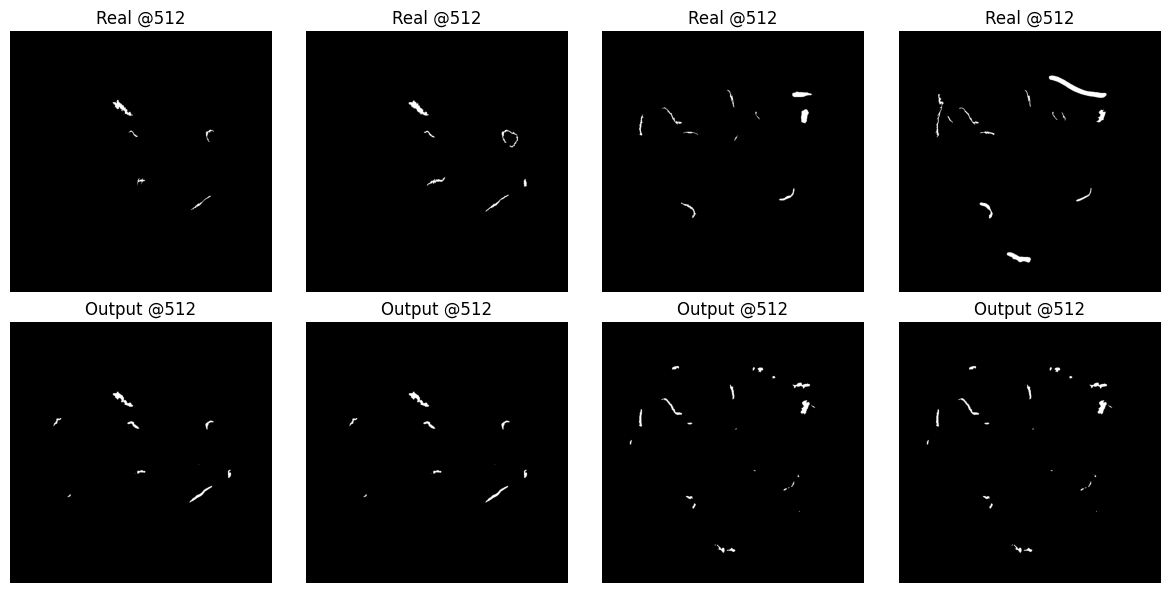

KeyboardInterrupt: 

In [37]:
epochs = 15
threshold, min_area = 0.5, 32
criterion = DiceLoss()
metric = DiceScore(threshold=threshold)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.2)

output = train(device, model, data_tr, data_val, dataset_sizes,
               criterion, optimizer, scheduler, metric, num_epochs=epochs,
               threshold=threshold, min_area=min_area)

model = output['model']
history_loss = output['history_loss']
history_metric = output['history_metric']
history_pq = output['history_pq']

## Training History

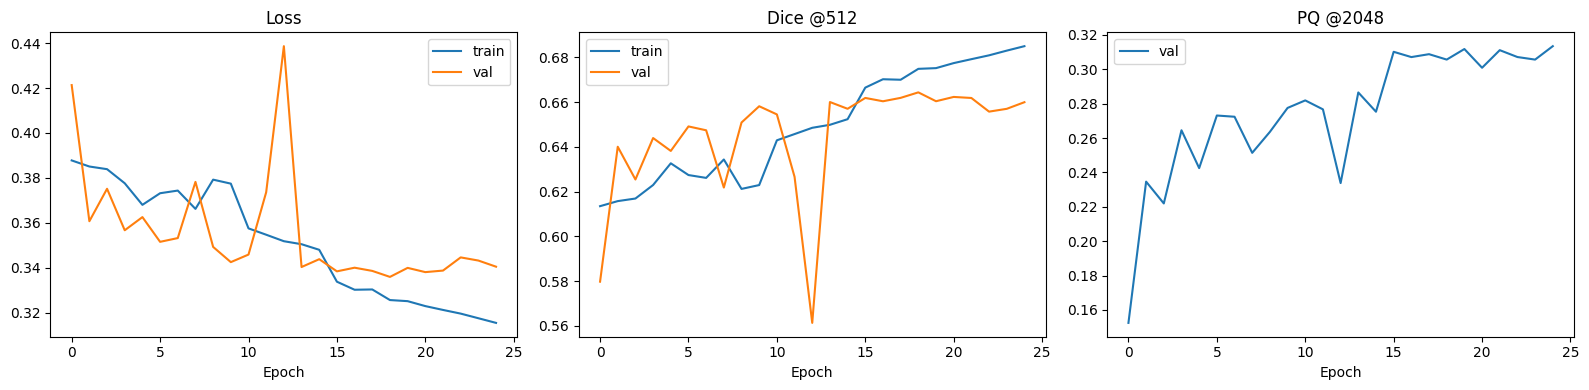

In [95]:
plt.figure(figsize=(16, 4))
for i, (history, title) in enumerate([(history_loss, 'Loss'), (history_metric, 'Dice @512')]):
    plt.subplot(1, 3, i + 1)
    plt.plot(history['train'], label='train')
    plt.plot(history['val'], label='val')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.legend()

plt.subplot(1, 3, 3)
plt.plot(history_pq, label='val')
plt.title('PQ @2048')
plt.xlabel('Epoch')
plt.legend()
plt.tight_layout()
plt.show()

## Model Evaluation

In [96]:
scores = evaluate(model, data_val, criterion, metric, threshold, min_area)
print(f'validation PQ: {scores["pq"]:.4f}')
print(f'TP: {int(scores["counts"][1])}, FP: {int(scores["counts"][2])}, FN: {int(scores["counts"][3])}')

Path('results').mkdir(exist_ok=True)
scores['per_record'].to_csv('results/validation.csv', index=False)
scores['per_record'].head()

validation PQ: 0.3135
TP: 1002, FP: 1282, FN: 815


,record_id,file_name,pq,tp,fp,fn
0,010202-20160223173514Mh,20160223173514Mh.jpeg,0.544846,5,2,0
1,010203-20160223173514Mh,20160223173514Mh.jpeg,0.452304,4,3,2
2,050101-20111218085014Th,20111218085014Th.jpeg,0.348587,6,6,4
3,050102-20111218085014Th,20111218085014Th.jpeg,0.161872,3,9,9
4,050103-20111218085014Th,20111218085014Th.jpeg,0.147751,3,9,11


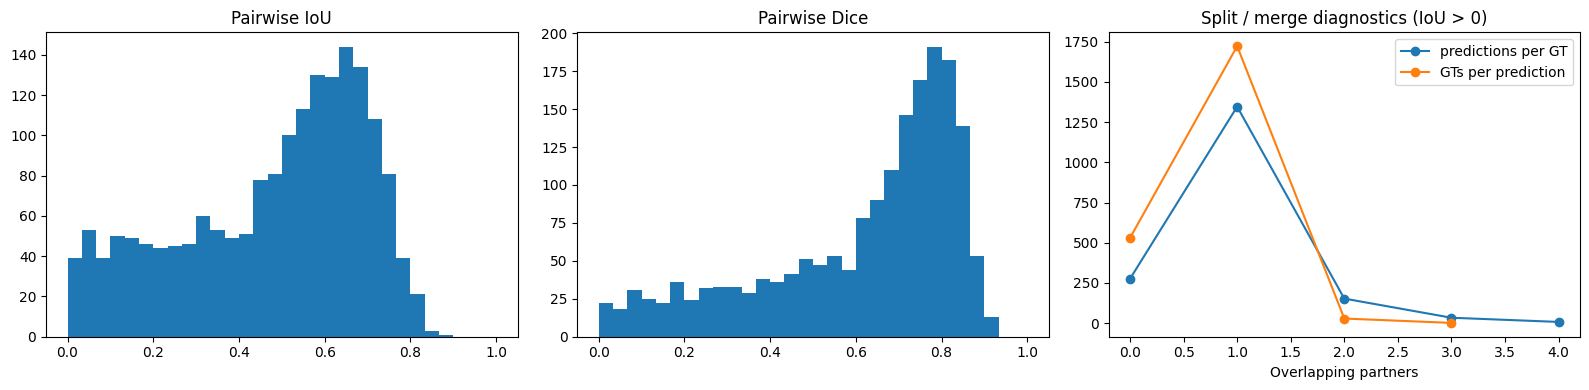

In [97]:
ious = np.concatenate([x[x > 0] for x in scores['overlaps']])
gt_degrees = np.concatenate([(x > 0).sum(1) for x in scores['overlaps']])
pred_degrees = np.concatenate([(x > 0).sum(0) for x in scores['overlaps']])

plt.figure(figsize=(16, 4))
for i, (values, title) in enumerate([(ious, 'Pairwise IoU'), (2 * ious / (1 + ious), 'Pairwise Dice')]):
    plt.subplot(1, 3, i + 1)
    plt.hist(values, bins=np.linspace(0, 1, 31))
    plt.title(title)

plt.subplot(1, 3, 3)
for values, label in [(gt_degrees, 'predictions per GT'), (pred_degrees, 'GTs per prediction')]:
    degrees, counts = np.unique(values, return_counts=True)
    plt.plot(degrees, counts, 'o-', label=label)
plt.title('Split / merge diagnostics (IoU > 0)')
plt.xlabel('Overlapping partners')
plt.legend()
plt.tight_layout()
plt.show()

## Test Predictions / Submission

Reload the best PQ checkpoint, then use only test JPEGs. Each row contains one non-overlapping 2048 x 2048 filament mask encoded as compressed COCO RLE counts. If an image has no detections, it contributes no rows; do not fabricate a filament. This cell creates a local CSV and does not upload it.

In [98]:
checkpoint = torch.load('models/unet_pq.pth', map_location='cpu', weights_only=True)
model = UNet(in_channels=1, out_channels=1, features=checkpoint['features']).to(device)
model.load_state_dict(checkpoint['state_dict'])
model.eval()

input_size = tuple(checkpoint['input_size'])
threshold, min_area = checkpoint['threshold'], checkpoint['min_area']
print(f'loaded epoch {checkpoint["epoch"]}, val PQ: {checkpoint["val_pq"]:.4f}')

loaded epoch 25, val PQ: 0.3135


In [99]:
@torch.no_grad()
def predict_rles(model, path, input_size=(512, 512), threshold=0.5, min_area=32):
    with Image.open(path) as img:
        image = np.array(img.convert('L'), dtype=np.float32) / 255.0

    shape = image.shape
    image = cv2.resize(image, input_size[::-1], interpolation=cv2.INTER_AREA)
    tensor = torch.from_numpy(image).unsqueeze(0).unsqueeze(0)
    model.eval()
    probability = model(tensor.to(next(model.parameters()).device))[0, 0].cpu().numpy()
    return probability_to_rles(probability, shape, threshold, min_area)


def make_submission(model, paths, input_size=(512, 512), threshold=0.5,
                    min_area=32, output_path='submission.csv'):
    rows = []
    for path in tqdm(paths):
        rles = predict_rles(model, path, input_size, threshold, min_area)
        for i, rle in enumerate(rles, 1):
            rows.append({'filament_id': f'{path.stem}_{i}',
                         'segmentation_rle': rle['counts'].decode('ascii')})

    submission = pd.DataFrame(rows, columns=['filament_id', 'segmentation_rle'])
    assert submission['filament_id'].is_unique
    submission.to_csv(output_path, index=False)
    print(f'{len(submission)} predicted filaments, {len(paths)} test images')
    return submission


submission = make_submission(model, test_paths, input_size, threshold, min_area)
submission.head()

100%|██████████| 180/180 [00:37<00:00,  4.83it/s]

1667 predicted filaments, 180 test images


,filament_id,segmentation_rle
0,20110120105534Ch_1,\`hi23jo15N021M;F0O01N3L3N1001O2N1O01010O0O01O...
1,20110120105534Ch_2,UjXQ22mo12O0O1J6O100O0O01010O0K41010O0C;2O100O...
2,20110130110334Ch_1,d_Re23ko13O7I8H10O102;C0O01O2N1O1O1008H0O10010...
3,20110214175414Mh_1,U]h[2>ao12O0O1I7N2O101N3N1POUOiRNk0Wm1WOfRNj0Y...
4,20110214175414Mh_2,i]hb22lo13O0001O0000O2M2O3N00O1O1O1001O2N1O000...
